# Structure-function overview — stable α = 1.5
Three rows: **N = 64, 128, 256**. Each row overlays **σE = 0, 1, 2** using consistent colors.

1. Set `DATA_ROOT` to the directory containing your moments FITS files (subdirectories are searched).
2. Run all cells. The inventory shows exactly which nine files are read.
3. The last cell optionally saves the figure.

The notebook only reads the FITS files. It expects the `TABLE` extension saved by your pipeline, with `log10 r` and `Unweighted B(r)`; bins with `N pairs <= 0` are excluded when that column exists. Edit `COLUMNS` if your saved names differ.

Separations follow your convention: $r=10^{\mathrm{log10\ r}}\,\mathrm{PIX}\,\mathrm{PC}$. Defaults below explicitly use **PIX = PC = 1** for synthetic maps. Set both overrides to `None` to read the corresponding FITS header values instead.

Error bars are **assumed 10% plotting errors**, as in your example, not measured uncertainties. Dashed horizontal lines show each sample's own $\sigma_\mathrm{pos}^2$ when available. Gray model curves call your `bfunc.bfunc00s` using each file's primary-header `R0`, `SIG2`, and `M3D`. Set `BFUNC_DIR` to the folder containing your existing `bfunc.py` (default: `py_modules`). Model variance always comes from the header, even when the horizontal variance reference uses a TABLE column.

Vertical reference lines read `LSCALE_X` (dashed) and `R0` (solid) from each file's primary header, with a TABLE-header fallback. Colors match σE. Identical values overlap. Header lengths are used directly in the plotted units; conversion factors and keyword names are configurable. Missing or nonpositive values produce a warning and that line is skipped.

Model grids use `np.linspace(r[0], r[-1], 400)` over each sample's retained separation range. `R0_FACTOR` also applies to the model radius (default 1). Set `SHOW_MODEL = False` to disable the model overlay.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
try:
    from IPython.display import display
except ImportError:
    display = print


In [2]:
# Main configuration
DATA_ROOT = Path("fits_ready")  # e.g. Path(r"C:\Users\javas\project\cubes")
MODEL = "exponential"
L = 16
#N_VALUES = (64, 128, 256)
N_VALUES = (256,)
SIGE_VALUES = (0, 1, 2)
FILE_TEMPLATE = "{model}_moments_N{N}_L{L}_sigE{sigE}.fits"
TABLE_HDU = "TABLE"

COLUMNS = {
    "log_r": "log10 r",
    "b2": "Unweighted B(r)",
    "count": "N pairs",                  # optional
    "sig2": "Unweighted sigma^2",        # optional; otherwise header SIG2
}
PIX_OVERRIDE = 1.0
PC_OVERRIDE = 1.0
X_LABEL = "Separation, pc (1 pixel = 1 pc)"

SHOW_ERRORS = True
RELATIVE_R_ERROR = 0.10
RELATIVE_B2_ERROR = 0.10
SHOW_SIG2 = True
SHARE_Y = True
COLORS = {0: "#0072B2", 1: "#D55E00", 2: "#009E73"}
MARKERS = {0: "o", 1: "s", 2: "^"}

# Vertical reference lines, read independently from every sample's header.
SHOW_LENGTH_SCALES = True
L_SCALE_KEY = "LSCALE_X"
R0_KEY = "R0"
# Header lengths are assumed to already use the plotted separation units.
# Set a factor to PIX * PC if that header length is instead stored in pixels.
L_SCALE_FACTOR = 1.0
R0_FACTOR = 1.0

# Model overlay: use your existing py_modules/bfunc.py implementation.
SHOW_MODEL = True
BFUNC_DIR = Path("py_modules")  # directory containing bfunc.py
MODEL_GRID_POINTS = 400
MODEL_COLOR = "0.8"


In [3]:
def find_input_files(root):
    root = Path(root).expanduser()
    if not root.is_dir():
        raise FileNotFoundError(f"Set DATA_ROOT to your FITS directory; not found: {root.resolve()}")
    paths, problems = {}, []
    for N in N_VALUES:
        for sigE in SIGE_VALUES:
            name = FILE_TEMPLATE.format(model=MODEL, N=N, L=L, sigE=sigE)
            matches = sorted(root.rglob(name))
            if len(matches) != 1:
                detail = "missing" if not matches else "multiple matches: " + "; ".join(map(str, matches))
                problems.append(f"{name}: {detail}")
            else:
                paths[N, sigE] = matches[0]
    if problems:
        raise FileNotFoundError("Expected exactly one file per sample. Narrow DATA_ROOT if needed.\n" + "\n".join(problems))
    return paths

paths = find_input_files(DATA_ROOT)
display(Table(rows=[(N, e, str(p)) for (N, e), p in paths.items()],
              names=("N", "sigE", "file")))


N,sigE,file
int32,int32,str50
256,0,fits_ready\exponential_moments_N256_L16_sigE0.fits
256,1,fits_ready\exponential_moments_N256_L16_sigE1.fits
256,2,fits_ready\exponential_moments_N256_L16_sigE2.fits


In [4]:
def numeric_column(table, name):
    # Explicit native float conversion also handles FITS big-endian arrays.
    values = np.ma.asarray(table[name], dtype=float).filled(np.nan)
    if values.ndim != 1:
        raise ValueError(f"Expected a scalar per row in {name!r}; shape={values.shape}")
    return values


def read_structure_function(path):
    with fits.open(path, memmap=False) as hdul:
        matches = [h for h in hdul if h.name.upper() == str(TABLE_HDU).upper()]
        if len(matches) != 1:
            raise ValueError(f"{path.name}: expected exactly one {TABLE_HDU!r} extension, found {len(matches)}")
        hdu = matches[0]
        if not isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)):
            raise ValueError(f"{path.name}: {TABLE_HDU!r} is not a table")
        table = Table(hdu.data)
        header = hdul[0].header.copy()
        table_header = hdu.header.copy()

    required = (COLUMNS["log_r"], COLUMNS["b2"])
    missing = [name for name in required if name not in table.colnames]
    if missing:
        raise KeyError(f"{path.name}: missing {missing}; available columns: {table.colnames}. Edit COLUMNS.")

    def scale(key, override):
        value = override if override is not None else header.get(key, table_header.get(key))
        if value is None:
            raise KeyError(f"{path.name}: missing {key}; set {key}_OVERRIDE explicitly")
        value = float(value)
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"{path.name}: {key} must be positive and finite")
        return value

    pix = scale("PIX", PIX_OVERRIDE)
    pc = scale("PC", PC_OVERRIDE)
    with np.errstate(over="ignore", invalid="ignore"):
        r = 10.0 ** numeric_column(table, COLUMNS["log_r"]) * pix * pc
    b2 = numeric_column(table, COLUMNS["b2"])
    valid = np.isfinite(r) & np.isfinite(b2) & (r > 0) & (b2 > 0)
    if COLUMNS["count"] in table.colnames:
        count = numeric_column(table, COLUMNS["count"])
        valid &= np.isfinite(count) & (count > 0)
    if not valid.any():
        raise ValueError(f"{path.name}: no positive, finite bins to plot on logarithmic axes")
    order = np.argsort(r[valid])

    # Variance is determined independently for every (N, sigE) sample.
    sig2, sig2_source = None, "not saved"
    if COLUMNS["sig2"] in table.colnames:
        values = numeric_column(table, COLUMNS["sig2"])
        values = values[np.isfinite(values)]
        if values.size:
            if not np.allclose(values, values[0], rtol=1e-6, atol=0):
                raise ValueError(f"{path.name}: variance column is not constant across rows")
            sig2, sig2_source = float(values[0]), "TABLE column"
    header_sig2 = header.get("SIG2", table_header.get("SIG2"))
    if sig2 is None and header_sig2 is not None:
        sig2, sig2_source = float(header_sig2), "SIG2 header"
    elif sig2 is not None and header_sig2 is not None:
        if not np.isclose(sig2, float(header_sig2), rtol=1e-6, atol=0):
            warnings.warn(f"{path.name}: TABLE variance differs from header SIG2; using TABLE")
    if sig2 is not None and (not np.isfinite(sig2) or sig2 <= 0):
        warnings.warn(f"{path.name}: variance is not positive and finite; omitting its reference line")
        sig2, sig2_source = None, "invalid"
    if SHOW_SIG2 and sig2 is None:
        warnings.warn(f"{path.name}: no usable variance; save SIG2 in the header to show its reference line")

    def header_length(key, factor):
        if not np.isfinite(factor) or factor <= 0:
            raise ValueError(f"{key}: conversion factor must be positive and finite")
        value = header.get(key, table_header.get(key))
        if value is None:
            if SHOW_LENGTH_SCALES:
                warnings.warn(f"{path.name}: missing {key}; omitting its vertical line")
            return None
        value = float(value) * factor
        if not np.isfinite(value) or value <= 0:
            if SHOW_LENGTH_SCALES:
                warnings.warn(f"{path.name}: invalid {key}={value}; omitting its vertical line")
            return None
        return value

    l_scale = header_length(L_SCALE_KEY, L_SCALE_FACTOR)
    r0 = header_length(R0_KEY, R0_FACTOR)
    # Model parameters come strictly from this file's PRIMARY header.
    # They are independent of the TABLE variance used by the reference line.
    model_params = None
    if SHOW_MODEL:
        missing = [key for key in ("M3D", "R0", "SIG2") if key not in header]
        if missing:
            raise KeyError(f"{path.name}: model overlay requires primary-header keys {missing}")
        model_params = {key: float(header[key]) for key in ("M3D", "R0", "SIG2")}
        if any(not np.isfinite(v) or v <= 0 for v in model_params.values()):
            raise ValueError(f"{path.name}: M3D, R0, and SIG2 must be positive and finite")
        model_params["R0"] *= R0_FACTOR
    return dict(model_params=model_params, l_scale=l_scale, r0=r0, path=path, r=r[valid][order], b2=b2[valid][order], sig2=sig2,
                sig2_source=sig2_source, pix=pix, pc=pc,
                n_total=len(table), n_used=int(valid.sum()))


samples = {key: read_structure_function(path) for key, path in paths.items()}
summary = Table(rows=[
    (N, e, d["n_total"], d["n_used"], d["pix"] * d["pc"],
     np.nan if d["sig2"] is None else d["sig2"], d["sig2_source"],
     np.nan if d["l_scale"] is None else d["l_scale"],
     np.nan if d["r0"] is None else d["r0"])
    for (N, e), d in samples.items()
], names=("N", "sigE", "bins_total", "bins_plotted", "scale_per_pixel", "sig2", "sig2_source", "L_SCALE_plot", "R0_plot"))
display(summary)


N,sigE,bins_total,bins_plotted,scale_per_pixel,sig2,sig2_source,L_SCALE_plot,R0_plot
int32,int32,int32,int32,float64,float64,str11,float64,float64
256,0,51,45,1.0,0.09981049094573317,SIG2 header,16.0,11.090354888959125
256,1,51,45,1.0,0.11630323753324157,SIG2 header,16.0,11.090354888959125
256,2,51,45,1.0,0.20902933970531212,SIG2 header,16.0,11.090354888959125


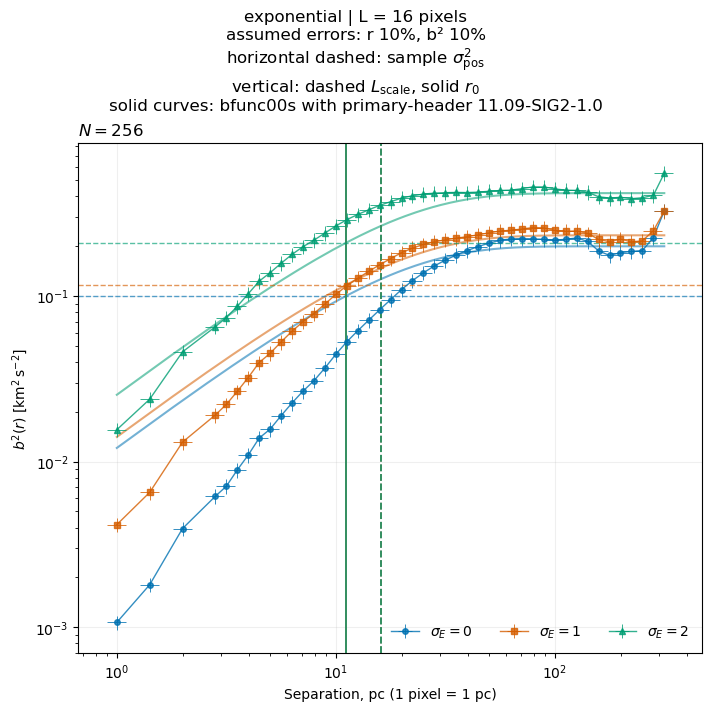

In [5]:
def plot_structure_functions(samples):
    if SHOW_MODEL:
        import sys
        import importlib
        module_dir = str(BFUNC_DIR.expanduser().resolve())
        if module_dir not in sys.path:
            sys.path.insert(0, module_dir)
        try:
            bfunc = importlib.import_module("bfunc")
        except ModuleNotFoundError as exc:
            raise ImportError(
                f"Cannot import bfunc (or one of its dependencies). "
                f"Set BFUNC_DIR to the folder containing your bfunc.py. Current: {module_dir}"
            ) from exc
        if not hasattr(bfunc, "bfunc00s"):
            raise AttributeError("Your bfunc module must define bfunc00s(r, r0, sig2, m3D)")
        if MODEL_GRID_POINTS < 2:
            raise ValueError("MODEL_GRID_POINTS must be at least 2")
    if SHOW_ERRORS and not (0 <= RELATIVE_R_ERROR < 1 and 0 <= RELATIVE_B2_ERROR < 1):
        raise ValueError("Relative errors must be in [0, 1) for logarithmic plotting")

    fig, axes = plt.subplots(
                                1, len(N_VALUES),
                                figsize=(7, 7),
                                sharex=True,
                                sharey=SHARE_Y,
                                squeeze=False,
                                constrained_layout=True,
                            )
    #fig, axes = plt.subplots(len(N_VALUES), 
    #                         1,
    #                         figsize=(5, 12),
    #                         sharex=True, 
    #                         sharey=SHARE_Y,
    #                         squeeze=False,
    #                         constrained_layout=True)
    for ax, N in zip(axes[0, :], N_VALUES):
        for sigE in SIGE_VALUES:
            d = samples[N, sigE]
            r, b2 = d["r"], d["b2"]
            color = COLORS[sigE]
            ax.errorbar(
                r, b2,
                xerr=RELATIVE_R_ERROR * r if SHOW_ERRORS else None,
                yerr=RELATIVE_B2_ERROR * b2 if SHOW_ERRORS else None,
                fmt=MARKERS[sigE] + "-", color=color, markersize=4,
                linewidth=1.0, elinewidth=0.7, capsize=0, alpha=0.8,
                label=rf"$\sigma_E={sigE}$",
            )
            if SHOW_MODEL:
                params = d["model_params"]
                # Scalar endpoints give a 1D grid (s[:-1] would give a 2D array).
                rgrid = np.linspace(r[0], r[-1], MODEL_GRID_POINTS)
                model_b2 = bfunc.bfunc00s(
                    rgrid, params["R0"], params["SIG2"], params["M3D"]
                )
                ax.plot(rgrid, model_b2, color=color, lw=1.5, zorder=1, alpha=0.55)
            if SHOW_SIG2 and d["sig2"] is not None:
                ax.axhline(d["sig2"], color=color, ls="--", lw=1, alpha=0.65)
            if SHOW_LENGTH_SCALES:
                if d["l_scale"] is not None:
                    ax.axvline(d["l_scale"], color=color, ls="--", lw=1.3, alpha=0.75)
                if d["r0"] is not None:
                    ax.axvline(d["r0"], color=color, ls="-", lw=1.3, alpha=0.75)
        ax.set(xscale="log", yscale="log",
               ylabel=r"$b^2(r)\ [\mathrm{km^2\,s^{-2}}]$")
        ax.set_title(rf"$N={N}$", loc="left", fontsize=12)
        ax.grid(which="major", alpha=0.20)
        ax.legend(loc="best", frameon=False, ncol=len(SIGE_VALUES))
    #axes[-1, 0].set_xlabel(X_LABEL)
    for ax in axes[0, :]:
        ax.set_xlabel(X_LABEL)
    details = []
    if SHOW_ERRORS:
        details.append(f"assumed errors: r {RELATIVE_R_ERROR:.0%}, b² {RELATIVE_B2_ERROR:.0%}")
    if SHOW_SIG2:
        details.append(r"horizontal dashed: sample $\sigma_\mathrm{pos}^2$")
    if SHOW_LENGTH_SCALES:
        details.append(r"vertical: dashed $L_\mathrm{scale}$, solid $r_0$")
    if SHOW_MODEL:
        details.append("solid curves: bfunc00s with primary-header " + f'{params["R0"]:.2f}' + "-SIG2-" + str(params["M3D"]))
    title = f"{MODEL} | L = {L} pixels"
    fig.suptitle(title + ("\n" + "\n".join(details) if details else ""), fontsize=12)
    return fig, axes[0, :]

fig, axes = plot_structure_functions(samples)
plt.show()


## Optional export and variance metadata
The plot uses a variance column when present, then falls back to the file's `SIG2` header. Assigning values to an earlier Python `rslt` dictionary does **not** automatically save them in the `rslt_` table. If needed, add this when building each FITS file (using the same valid velocity sample used in the SF calculation):

```python
primary.header["SIG2"] = (float(np.var(vv)), "Unweighted velocity-map variance")
```

Use the map variance for each individual σE sample, not one common input 3D-field variance. The notebook does not infer variance from the largest-separation SF bin.


In [6]:
SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")
if SAVE_FIGURE:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    stem = f"SF_overview_{MODEL}_L{L}"
    for suffix in ("png", "pdf"):
        output = OUTPUT_DIR / f"{stem}.{suffix}"
        fig.savefig(output, dpi=250, bbox_inches="tight")
        print(output.resolve())


C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\SF_overview_exponential_L16.png
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\SF_overview_exponential_L16.pdf
